# H&M Customer Segmentation: RFM Analysis

Customer segmentation using the [H&M Personalized Fashion Recommendations dataset](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations) (Kaggle, 2022). The dataset covers 31.8M transactions from 1.4M customers across a two-year period (Sept 2018 – Sept 2020).

The goal is to identify behaviorally distinct customer groups using RFM features: Recency, Frequency, and Monetary value, and characterize each group's category preferences and associated customer attributes.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Plot styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## Data Loading

In [32]:
transactions = pd.read_csv('data/transactions_clean.csv', parse_dates=['t_dat'])
customers = pd.read_csv('data/customers.csv')
articles = pd.read_csv('data/articles.csv')

print(f"Transactions: {transactions.shape}")
print(f"Customers: {customers.shape}")
print(f"Articles: {articles.shape}")
print(f"Date range: {transactions['t_dat'].min().date()} to {transactions['t_dat'].max().date()}")

Transactions: (31788324, 5)
Customers: (1371980, 7)
Articles: (105542, 25)
Date range: 2018-09-20 to 2020-09-22


## RFM Construction

Standard RFM features: recency (days since last purchase), frequency (number of transactions), and monetary value (spend per transaction). We start with a raw aggregation and check correlations before deciding on any preprocessing.

In [33]:
snapshot_date = transactions['t_dat'].max() + pd.Timedelta(days=1)

rfm = transactions.groupby('customer_id').agg(
    recency=('t_dat', lambda x: (snapshot_date - x.max()).days),
    frequency=('article_id', 'count'),
    monetary=('price', 'sum')  
).reset_index()

# Join customer attributes
rfm = rfm.merge(
    customers[['customer_id', 'age', 'fashion_news_frequency', 'club_member_status']], 
    on='customer_id', how='left'
)

print(rfm.shape)
print(rfm[['recency', 'frequency', 'monetary']].describe())

(1362281, 7)
            recency     frequency      monetary
count  1.362281e+06  1.362281e+06  1.362281e+06
mean   2.361484e+02  2.333463e+01  6.493858e-01
std    2.211188e+02  3.924225e+01  1.197582e+00
min    1.000000e+00  1.000000e+00  7.627119e-04
25%    4.900000e+01  3.000000e+00  8.806780e-02
50%    1.520000e+02  9.000000e+00  2.455932e-01
75%    3.990000e+02  2.700000e+01  7.011864e-01
max    7.340000e+02  1.895000e+03  5.767641e+01


## Feature Correlations

Before preprocessing, it's worth checking how correlated the raw RFM features are. High correlation between F and M would suggest some redundancy in the features we're feeding into PCA.

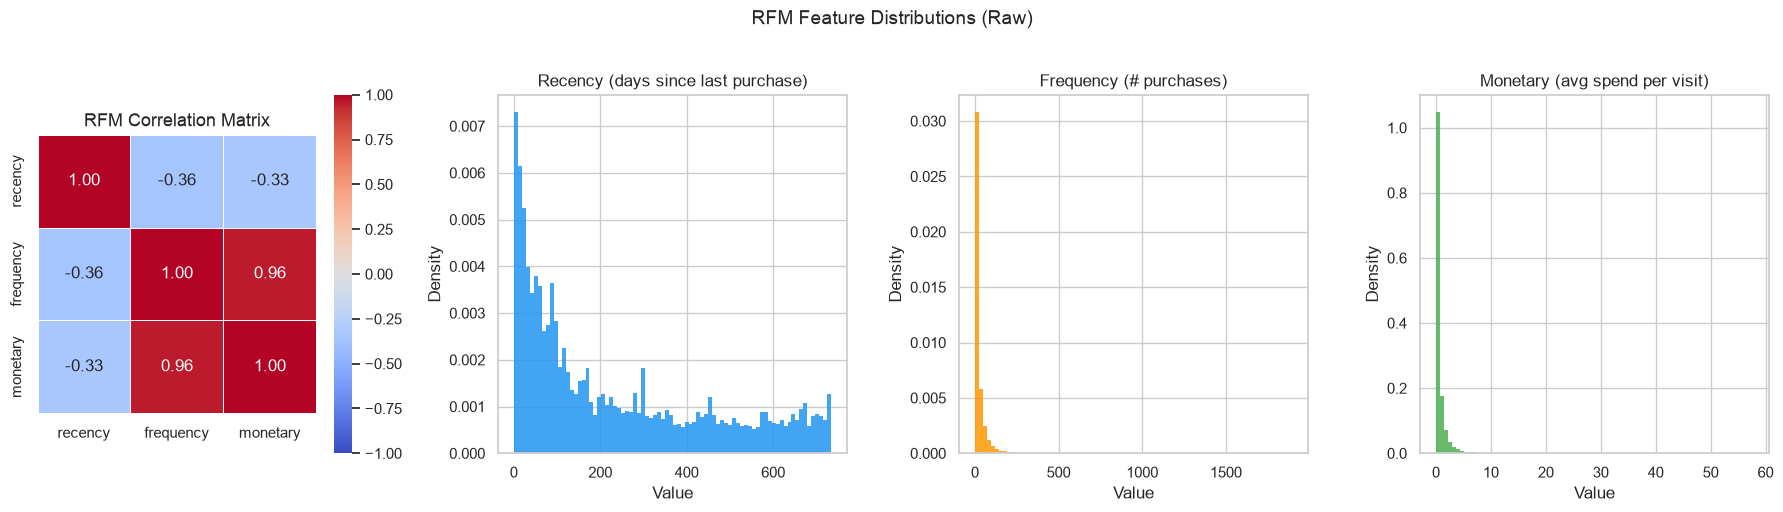

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Correlation heatmap
corr = rfm[['recency', 'frequency', 'monetary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            ax=axes[0])
axes[0].set_title('RFM Correlation Matrix', fontsize=13)

# One histogram per feature
for i, (col, color, label) in enumerate(zip(
    ['recency', 'frequency', 'monetary'],
    ['#2196F3', '#FF9800', '#4CAF50'],
    ['Recency (days since last purchase)', 'Frequency (# purchases)', 'Monetary (avg spend per visit)']
)):
    axes[i+1].hist(rfm[col], bins=80, color=color, density=True, edgecolor='none', alpha=0.85)
    axes[i+1].set_title(label, fontsize=12)
    axes[i+1].set_xlabel('Value')
    axes[i+1].set_ylabel('Density')

plt.suptitle('RFM Feature Distributions (Raw)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Monetary and frequency are highly correlated. Total spend is partly a function of how often a customer shops. There's also a moderate negative correlation between recency and frequency. Both of these limit how informative PCA can be when run on raw features.

To address this: (1) redefine monetary as average spend per transaction rather than total, and (2) residualize recency on frequency so it reflects whether a customer is more or less recently active than expected given their purchase frequency.

In [35]:
snapshot_date = transactions['t_dat'].max() + pd.Timedelta(days=1)

rfm = transactions.groupby('customer_id').agg(
    recency=('t_dat', lambda x: (snapshot_date - x.max()).days),
    frequency=('article_id', 'count'),
    monetary=('price', 'mean')  # avg spend per transaction (avoids collinearity with frequency)
).reset_index()

# Residualize recency on frequency to remove spurious negative correlation
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(rfm[['frequency']], rfm['recency'])
rfm['recency_resid'] = rfm['recency'] - lr.predict(rfm[['frequency']])

# Join customer attributes
rfm = rfm.merge(
    customers[['customer_id', 'age', 'fashion_news_frequency', 'club_member_status']], 
    on='customer_id', how='left'
)

print(rfm.shape)
print(rfm[['recency', 'recency_resid', 'frequency', 'monetary']].describe())

(1362281, 8)
            recency  recency_resid     frequency      monetary
count  1.362281e+06   1.362281e+06  1.362281e+06  1.362281e+06
mean   2.361484e+02   1.864013e-14  2.333463e+01  2.875476e-02
std    2.211188e+02   2.064251e+02  3.924225e+01  1.429338e-02
min    1.000000e+00  -2.802592e+02  1.000000e+00  7.627119e-04
25%    4.900000e+01  -1.681406e+02  3.000000e+00  2.095763e-02
50%    1.520000e+02  -6.564641e+01  9.000000e+00  2.613317e-02
75%    3.990000e+02   1.500733e+02  2.700000e+01  3.336083e-02
max    7.340000e+02   3.552179e+03  1.895000e+03  5.067797e-01


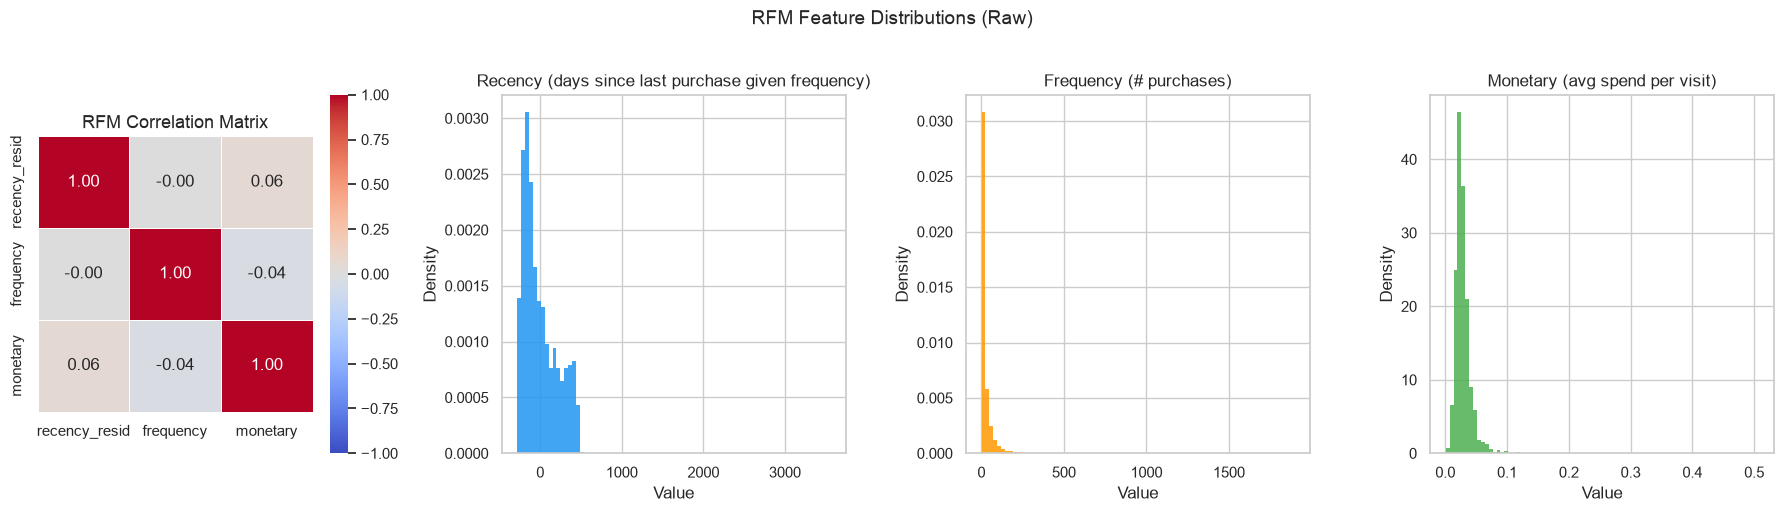

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Correlation heatmap
corr = rfm[['recency_resid', 'frequency', 'monetary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            ax=axes[0])
axes[0].set_title('RFM Correlation Matrix', fontsize=13)

# One histogram per feature
for i, (col, color, label) in enumerate(zip(
    ['recency_resid', 'frequency', 'monetary'],
    ['#2196F3', '#FF9800', '#4CAF50'],
    ['Recency (days since last purchase given frequency)', 'Frequency (# purchases)', 'Monetary (avg spend per visit)']
)):
    axes[i+1].hist(rfm[col], bins=80, color=color, density=True, edgecolor='none', alpha=0.85)
    axes[i+1].set_title(label, fontsize=12)
    axes[i+1].set_xlabel('Value')
    axes[i+1].set_ylabel('Density')

plt.suptitle('RFM Feature Distributions (Raw)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

We have successfully decorrelated our features and can now move forward with PCA. 

## Preprocessing

Frequency and monetary are right-skewed, so we apply a `log1p` transformation before standardizing. Recency residual can be negative so we skip the log transform for that feature.

In [37]:
rfm_model = rfm[['recency_resid', 'frequency', 'monetary']].copy()

# Log transform skewed dimensions (recency_resid can be negative so we skip it)
rfm_model['frequency'] = np.log1p(rfm_model['frequency'])
rfm_model['monetary'] = np.log1p(rfm_model['monetary'])

# Standardize
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_model)
rfm_scaled = pd.DataFrame(rfm_scaled, columns=['recency_resid', 'frequency', 'monetary'])

print(rfm_scaled.describe().round(3))

       recency_resid    frequency     monetary
count    1362281.000  1362281.000  1362281.000
mean          -0.000       -0.000       -0.000
std            1.000        1.000        1.000
min           -1.358       -1.476       -2.032
25%           -0.815       -0.892       -0.555
50%           -0.318       -0.121       -0.182
75%            0.727        0.745        0.337
max           17.208        4.292       28.206


## PCA

With three features, two principal components should capture most of the variance. We run PCA mainly for the 2D visualization — the clustering itself runs on the full 3D scaled data.

In [38]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]:.1%}")
print(f"Variance explained by PC2: {pca.explained_variance_ratio_[1]:.1%}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.1%}")
print(f"\nPC1 loadings: recency={pca.components_[0,0]:.3f}, frequency={pca.components_[0,1]:.3f}, monetary={pca.components_[0,2]:.3f}")
print(f"PC2 loadings: recency={pca.components_[1,0]:.3f}, frequency={pca.components_[1,1]:.3f}, monetary={pca.components_[1,2]:.3f}")

Variance explained by PC1: 44.1%
Variance explained by PC2: 31.8%
Total variance explained: 75.9%

PC1 loadings: recency=-0.617, frequency=0.677, monetary=-0.401
PC2 loadings: recency=-0.458, frequency=0.106, monetary=0.883


PC1 loads positively on frequency and negatively on recency, which roughly captures overall engagement. PC2 loads heavily on monetary, separating customers by spend per visit independent of how often they shop.

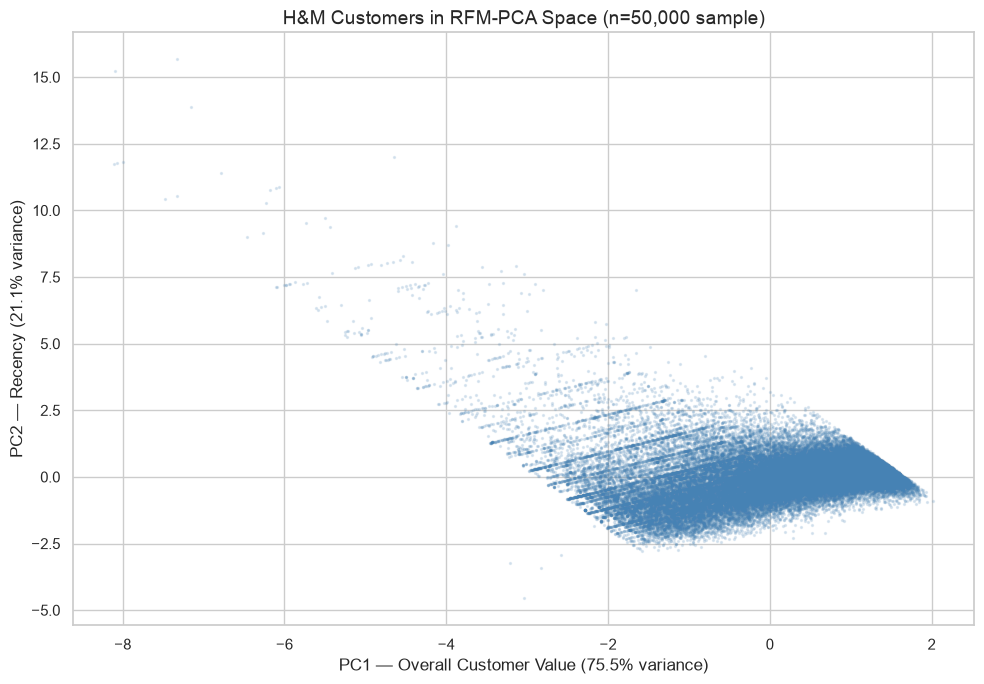

In [39]:
# Sample for plotting
np.random.seed(42)
sample_idx = np.random.choice(len(rfm_pca), size=50000, replace=False)

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    rfm_pca[sample_idx, 0], 
    rfm_pca[sample_idx, 1],
    alpha=0.15, s=2, c='steelblue'
)

ax.set_xlabel(f'PC1 — Overall Customer Value (75.5% variance)', fontsize=12)
ax.set_ylabel(f'PC2 — Recency (21.1% variance)', fontsize=12)
ax.set_title('H&M Customers in RFM-PCA Space (n=50,000 sample)', fontsize=14)
plt.tight_layout()
plt.show()

## Clustering

We use the silhouette score to pick k, testing k=2 through 8 on a 100K sample.

In [40]:
# Test k=2 through 8 on a sample for speed
sample_idx_km = np.random.choice(len(rfm_scaled), size=100000, replace=False)
rfm_sample = rfm_scaled.iloc[sample_idx_km]

silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_sample)
    score = silhouette_score(rfm_sample, labels, sample_size=10000)
    silhouette_scores.append(score)
    print(f"k={k}: silhouette={score:.4f}")

k=2: silhouette=0.3571
k=3: silhouette=0.3725
k=4: silhouette=0.3387
k=5: silhouette=0.3374
k=6: silhouette=0.3010
k=7: silhouette=0.2855
k=8: silhouette=0.2923


k=3 wins (silhouette = 0.37). Fitting on the full dataset below.

In [41]:
# Fit on full dataset
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['cluster'] = kmeans.fit_predict(rfm_scaled).astype(int)

# Add PCA coordinates
rfm['pc1'] = rfm_pca[:, 0]
rfm['pc2'] = rfm_pca[:, 1]

print(rfm['cluster'].value_counts().sort_index())

cluster
0    119561
1    831603
2    411117
Name: count, dtype: int64


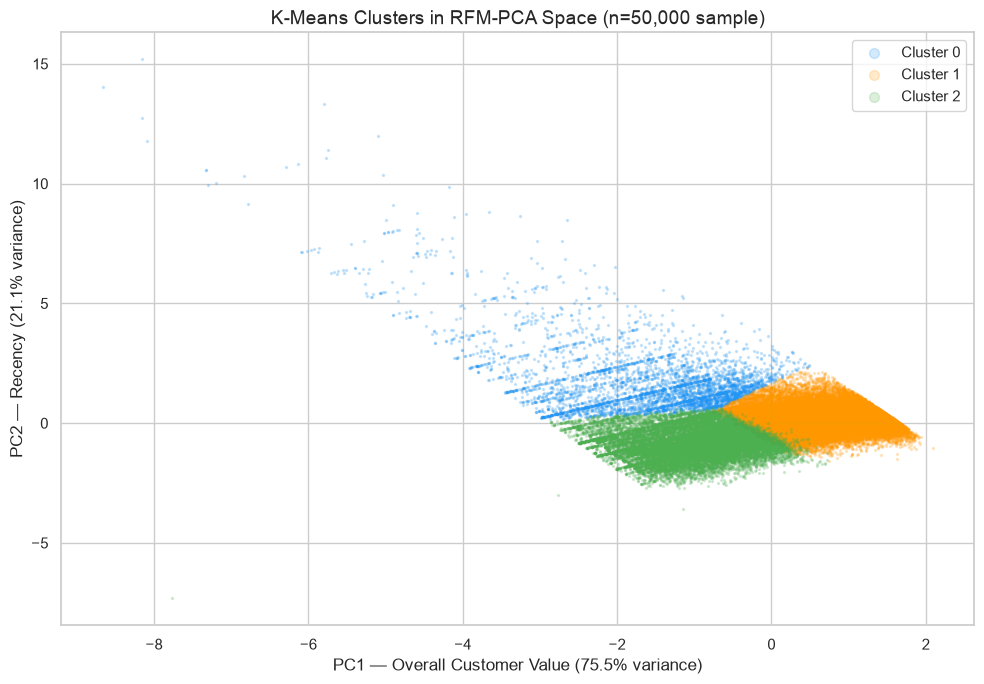

In [42]:
cluster_colors = {0: '#2196F3', 1: '#FF9800', 2: '#4CAF50'}
cluster_labels = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2'}

fig, ax = plt.subplots(figsize=(10, 7))

sample_idx = np.random.choice(len(rfm), size=50000, replace=False)
rfm_sample = rfm.iloc[sample_idx]

for cluster_id in sorted(rfm['cluster'].unique()):
    mask = rfm_sample['cluster'] == cluster_id
    ax.scatter(
        rfm_sample.loc[mask, 'pc1'],
        rfm_sample.loc[mask, 'pc2'],
        alpha=0.2, s=2,
        c=cluster_colors[cluster_id],
        label=cluster_labels[cluster_id]
    )

ax.set_xlabel('PC1 — Overall Customer Value (75.5% variance)', fontsize=12)
ax.set_ylabel('PC2 — Recency (21.1% variance)', fontsize=12)
ax.set_title('K-Means Clusters in RFM-PCA Space (n=50,000 sample)', fontsize=14)
ax.legend(markerscale=5, fontsize=11)
plt.tight_layout()
plt.show()

## Cluster Profiles

Let's look at how the clusters differ on the raw RFM metrics.

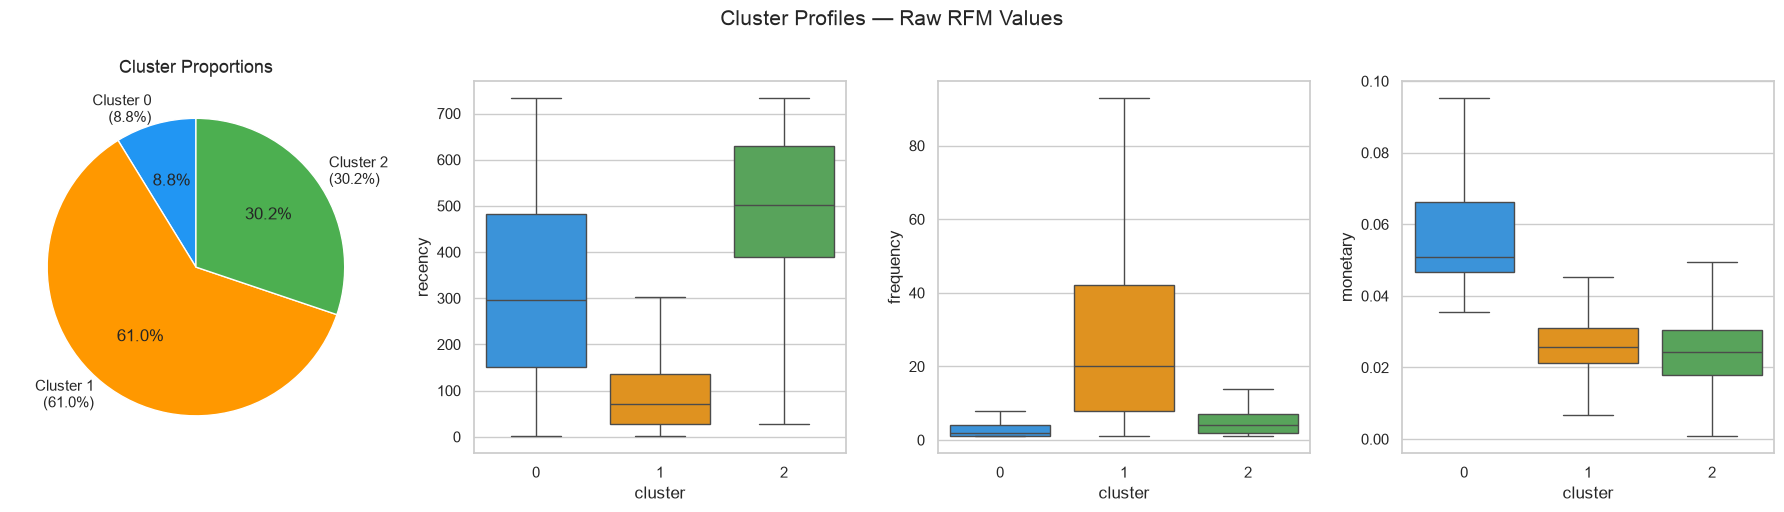

         recency  frequency  monetary
cluster                              
0          297.0        2.0      0.05
1           70.0       20.0      0.03
2          502.0        4.0      0.02


In [43]:
# --- Cluster sizes ---
cluster_counts = rfm['cluster'].value_counts().sort_index()
cluster_pct = (cluster_counts / len(rfm) * 100).round(1)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Pie chart
axes[0].pie(cluster_counts, labels=[f'Cluster {i}\n({cluster_pct[i]}%)' for i in range(3)],
            colors=['#2196F3', '#FF9800', '#4CAF50'],
            autopct='%1.1f%%', startangle=90)
axes[0].set_title('Cluster Proportions', fontsize=13)

# RFM boxplots per cluster
rfm_plot = rfm[['recency', 'frequency', 'monetary', 'cluster']].copy()
rfm_plot['cluster'] = rfm_plot['cluster'].astype(int)

palette_list = ['#2196F3', '#FF9800', '#4CAF50']

for i, metric in enumerate(['recency', 'frequency', 'monetary']):
    sns.boxplot(data=rfm_plot, x='cluster', y=metric, hue='cluster',
            palette=palette_list, legend=False,
            ax=axes[i+1], showfliers=False)

plt.suptitle('Cluster Profiles — Raw RFM Values', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# Numeric summary
print(rfm.groupby('cluster')[['recency', 'frequency', 'monetary']].median().round(2))

In [44]:
cluster_names = {1: 'Loyalists', 0: 'High-Value Occasionals', 2: 'Lapsed'}
rfm['segment'] = rfm['cluster'].map(cluster_names)
print(rfm['segment'].value_counts())

segment
Loyalists                 831603
Lapsed                    411117
High-Value Occasionals    119561
Name: count, dtype: int64


We label our clusters based on these RFM characteristics. "Loyalists" (cluster 1) shop frequently and recently. "High Value Occassionals" shop less frequently, but tend to spend more when they do visit, and our "Lapsed" cluster reflects customers that neither visit often nor spend much compared to the shoppers in the other clusters.

## Product Category Preferences by Segment

Now that we have segment labels, we can look at what each group buys. We merge transaction records back with the segment assignments and compute transaction share by category (volume) and average spend per transaction by category (price point).

In [45]:
# Merge segment labels onto transactions
transactions_seg = transactions.merge(
    rfm[['customer_id', 'segment']], on='customer_id', how='inner'
)

# Merge article metadata to get product group
transactions_seg = transactions_seg.merge(
    articles[['article_id', 'product_group_name']], on='article_id', how='left'
)

# Count transactions per segment x product group
cat_seg = (transactions_seg
    .groupby(['segment', 'product_group_name'])
    .size()
    .reset_index(name='n_transactions')
)

# Compute share within each segment
cat_seg['seg_total'] = cat_seg.groupby('segment')['n_transactions'].transform('sum')
cat_seg['pct_of_segment'] = cat_seg['n_transactions'] / cat_seg['seg_total'] * 100

# Also compute overall share (baseline)
overall = (transactions_seg
    .groupby('product_group_name')
    .size()
    .reset_index(name='n_total')
)
overall['pct_overall'] = overall['n_total'] / overall['n_total'].sum() * 100

# Merge and compute index (how much over/under baseline)
cat_seg = cat_seg.merge(overall[['product_group_name', 'pct_overall']], on='product_group_name')
cat_seg['index'] = (cat_seg['pct_of_segment'] / cat_seg['pct_overall'] * 100).round(1)

print(cat_seg.shape)
print(cat_seg['product_group_name'].nunique(), "product groups")

(54, 7)
19 product groups


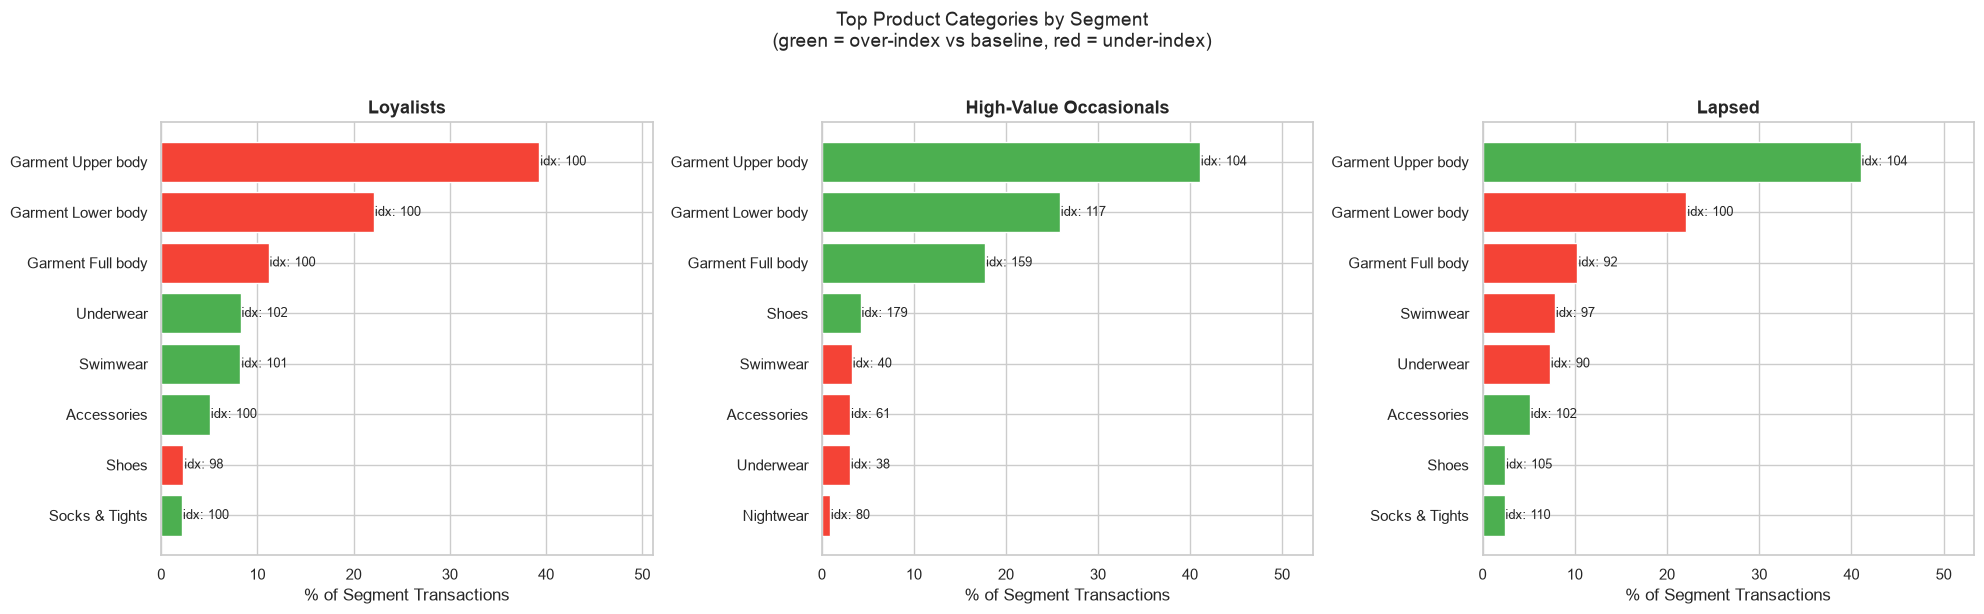

In [46]:
top_n = 8
segments = ['Loyalists', 'High-Value Occasionals', 'Lapsed']

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

for ax, seg in zip(axes, segments):
    data = (cat_seg[cat_seg['segment'] == seg]
            .nlargest(top_n, 'pct_of_segment')
            .sort_values('pct_of_segment'))
    
    colors = ['#4CAF50' if x >= 100 else '#F44336' for x in data['index']]
    
    bars = ax.barh(data['product_group_name'], data['pct_of_segment'], color=colors)
    
    # Add index labels on bars
    for bar, idx in zip(bars, data['index']):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                f'idx: {idx:.0f}', va='center', fontsize=9)
    
    ax.set_title(seg, fontsize=13, fontweight='bold')
    ax.set_xlabel('% of Segment Transactions')
    ax.set_xlim(0, data['pct_of_segment'].max() * 1.3)

plt.suptitle('Top Product Categories by Segment\n(green = over-index vs baseline, red = under-index)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

The category mix is similar across all three segments. Garment Upper Body dominates across all customer segments (~40% of transactions). Let's reexamine our categories looking instead for differences in the average spend across our segments.

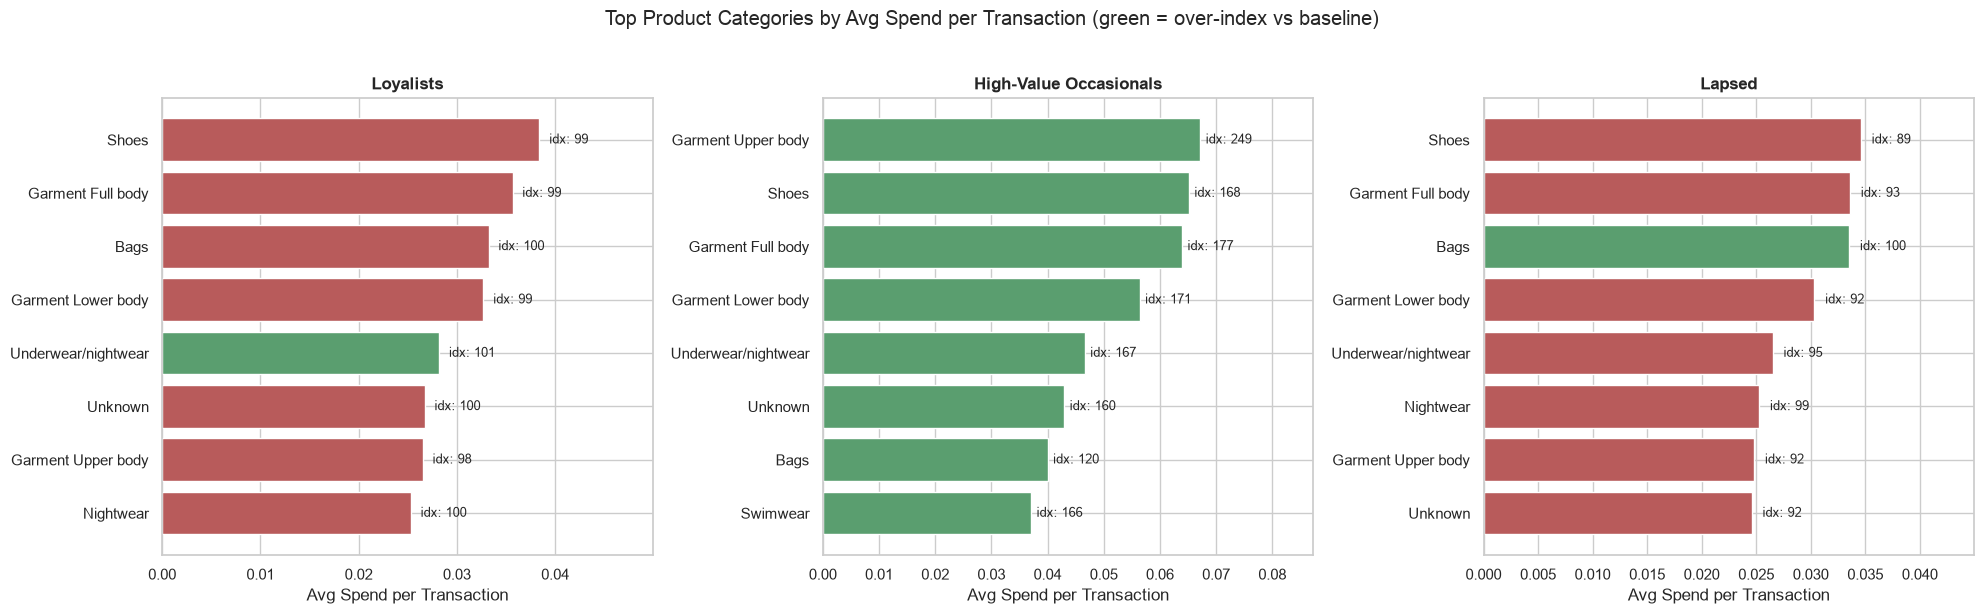

In [47]:
spend_seg = (transactions_seg
    .groupby(['segment', 'product_group_name'])
    .agg(avg_spend=('price', 'mean'))
    .reset_index()
)

overall_spend = (transactions_seg
    .groupby('product_group_name')
    .agg(avg_spend_overall=('price', 'mean'))
    .reset_index()
)

spend_seg = spend_seg.merge(overall_spend, on='product_group_name')
spend_seg['index'] = (spend_seg['avg_spend'] / spend_seg['avg_spend_overall'] * 100).round(1)

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)
segments = ['Loyalists', 'High-Value Occasionals', 'Lapsed']
top_n = 8

for ax, seg in zip(axes, segments):
    data = (spend_seg[spend_seg['segment'] == seg]
            .nlargest(top_n, 'avg_spend')
            .sort_values('avg_spend'))
    
    colors = ['#5A9E6F' if x >= 100 else '#B85B5B' for x in data['index']]
    bars = ax.barh(data['product_group_name'], data['avg_spend'], color=colors)
    
    for bar, idx in zip(bars, data['index']):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'idx: {idx:.0f}', va='center', fontsize=9)
    
    ax.set_title(seg, fontweight='bold')
    ax.set_xlabel('Avg Spend per Transaction')
    ax.set_xlim(0, data['avg_spend'].max() * 1.3)

plt.suptitle('Top Product Categories by Avg Spend per Transaction (green = over-index vs baseline)', y=1.02)
plt.tight_layout()
plt.show()

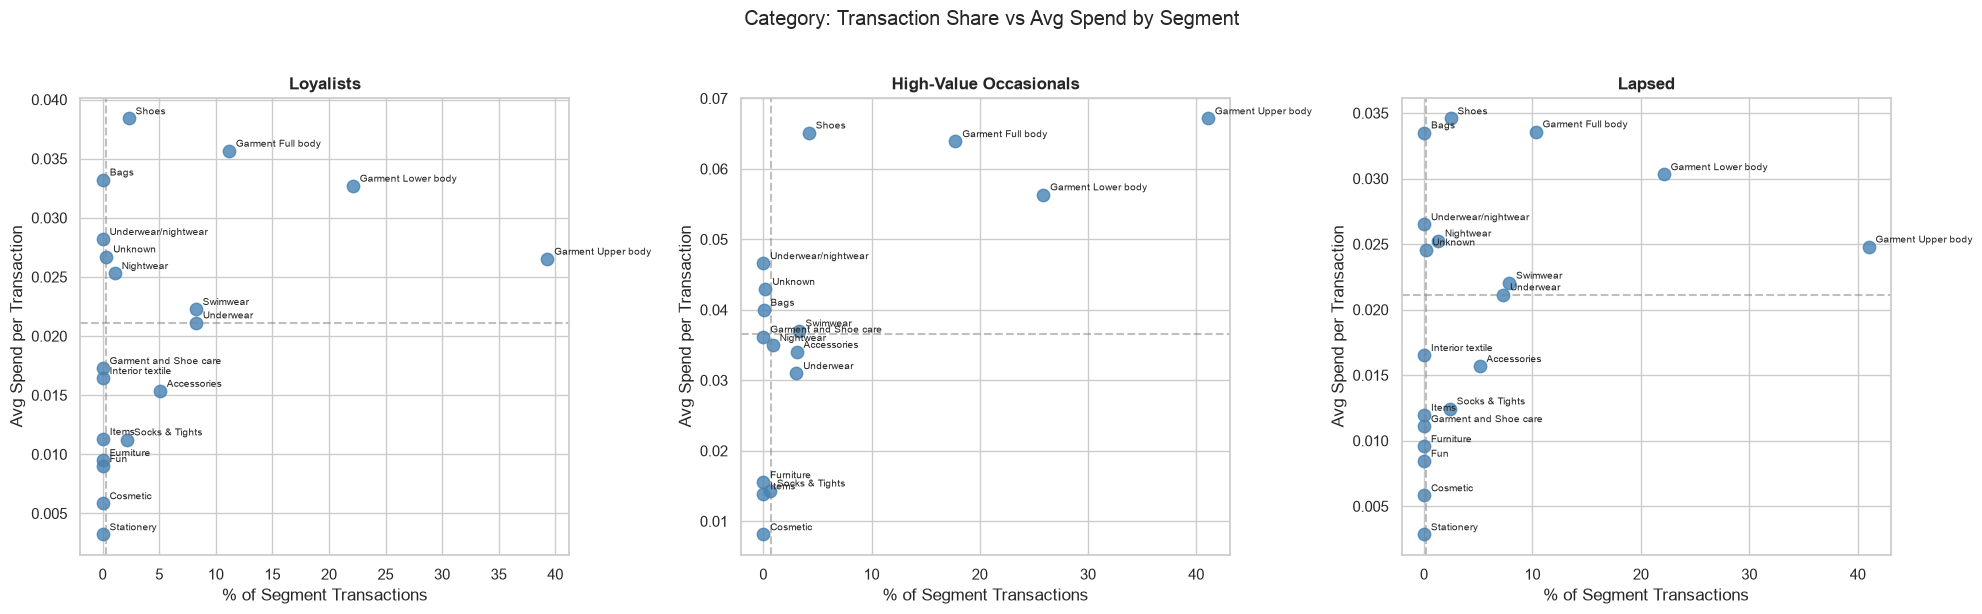

In [48]:
opp = cat_seg[['segment', 'product_group_name', 'pct_of_segment']].merge(
    spend_seg[['segment', 'product_group_name', 'avg_spend', 'index']],
    on=['segment', 'product_group_name']
)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, seg in zip(axes, segments):
    data = opp[opp['segment'] == seg]
    
    ax.scatter(data['pct_of_segment'], data['avg_spend'],
               s=80, alpha=0.8, color='steelblue')
    
    for _, row in data.iterrows():
        ax.annotate(row['product_group_name'], 
                    xy=(row['pct_of_segment'], row['avg_spend']),
                    xytext=(5, 3), textcoords='offset points', fontsize=7.5)
    
    ax.axvline(data['pct_of_segment'].median(), color='gray', linestyle='--', alpha=0.5)
    ax.axhline(data['avg_spend'].median(), color='gray', linestyle='--', alpha=0.5)
    
    ax.set_title(seg, fontweight='bold')
    ax.set_xlabel('% of Segment Transactions')
    ax.set_ylabel('Avg Spend per Transaction')

plt.suptitle('Category: Transaction Share vs Avg Spend by Segment', y=1.02)
plt.tight_layout()
plt.show()

While all three groups are generally spending on the same product categories, we can see differences in the spend per transaction between our customer segments. For example, High-Value Occasionals consistently over-index on spend per transaction across every category, suggesting that they are buying at higher price points within those categories.

This raises an obvious question: given that Loyalists shop the same categories at much higher volume, what's the revenue opportunity if we could shift their spend per visit upward? We can get a rough estimate for this by comparing spend per transaction for Loyalists vs HVOs in each of Loyalists' top categories, then multiplying by transaction volume:

$$\text{uplift} = (\bar{spend}_{HVO} - \bar{spend}_{Loyalist}) \times n\_transactions_{Loyalist}$$

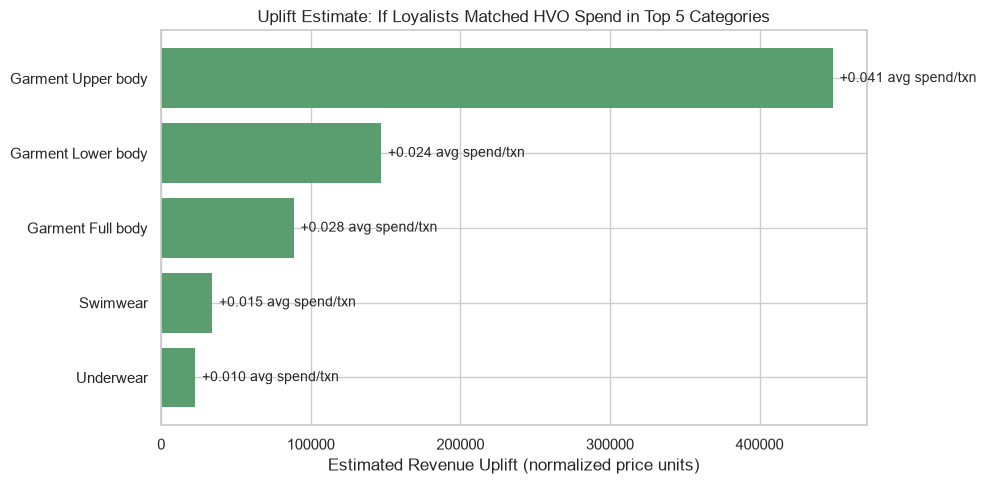

,product_group_name,loyalist_spend,hvo_spend,spend_gap,revenue_uplift
3,Underwear,0.0211,0.0310,0.0098,22844.8768
4,Swimwear,0.0223,0.0370,0.0148,34200.0357
2,Garment Full body,0.0357,0.0639,0.0282,88671.7266
1,Garment Lower body,0.0327,0.0564,0.0237,147143.6449
0,Garment Upper body,0.0265,0.0672,0.0406,449056.9265


In [49]:
txn_counts = (transactions_seg
    .groupby(['segment', 'product_group_name'])
    .size()
    .reset_index(name='n_transactions')
)

opp2 = opp.merge(txn_counts, on=['segment', 'product_group_name'])

loyalist_top = (opp2[opp2['segment'] == 'Loyalists']
    .nlargest(5, 'pct_of_segment')[['product_group_name', 'avg_spend', 'n_transactions']]
    .rename(columns={'avg_spend': 'loyalist_spend', 'n_transactions': 'loyalist_txns'})
)

hvo_spend = (opp2[opp2['segment'] == 'High-Value Occasionals']
    [['product_group_name', 'avg_spend']]
    .rename(columns={'avg_spend': 'hvo_spend'})
)

uplift_df = loyalist_top.merge(hvo_spend, on='product_group_name')
uplift_df['spend_gap'] = uplift_df['hvo_spend'] - uplift_df['loyalist_spend']
uplift_df['revenue_uplift'] = uplift_df['spend_gap'] * uplift_df['loyalist_txns']
uplift_df = uplift_df.sort_values('revenue_uplift', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(uplift_df['product_group_name'], uplift_df['revenue_uplift'],
               color='#5A9E6F', edgecolor='none')

for bar, gap in zip(bars, uplift_df['spend_gap']):
    ax.text(bar.get_width() + uplift_df['revenue_uplift'].max() * 0.01,
            bar.get_y() + bar.get_height()/2,
            f'+{gap:.3f} avg spend/txn', va='center', fontsize=10)

ax.set_xlabel('Estimated Revenue Uplift (normalized price units)')
ax.set_title("Uplift Estimate: If Loyalists Matched HVO Spend in Top 5 Categories")
plt.tight_layout()
plt.show()

uplift_df[['product_group_name', 'loyalist_spend', 'hvo_spend', 'spend_gap', 'revenue_uplift']].round(4)

We can identify Garment Upper Body as the stand-out result here. Even a small shift in spend per visit in this category adds up quickly given the transaction volume. The other categories show the same direction but at a smaller scale.

## Customer Attributes by Segment

A quick look at whether age, newsletter subscription, or club membership differ across segments.

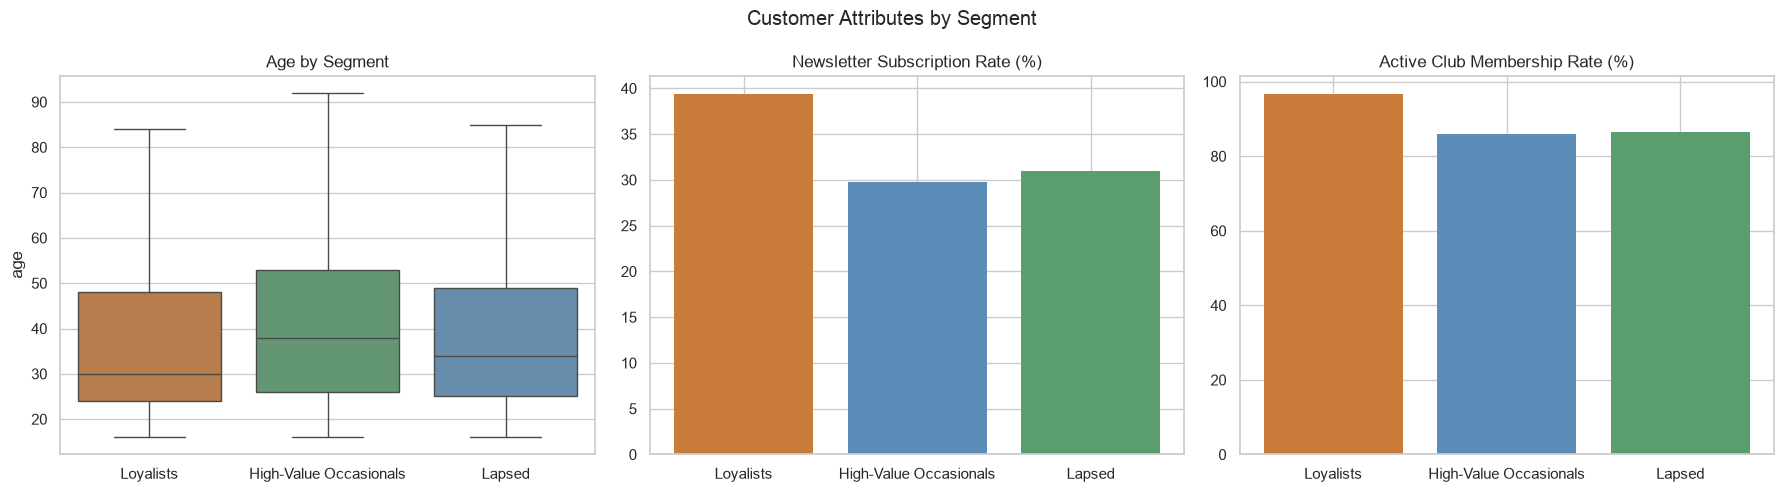

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

seg_order = ['Loyalists', 'High-Value Occasionals', 'Lapsed']
palette_seg = ['#C97B3A', '#5B8DB8', '#5A9E6F']

sns.boxplot(data=rfm.dropna(subset=['age']), x='segment', y='age',
            order=seg_order, hue='segment', palette=palette_seg,
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_title('Age by Segment')
axes[0].set_xlabel('')

newsletter = (rfm.groupby('segment')['fashion_news_frequency']
    .apply(lambda x: (x != 'NONE').mean() * 100)
    .reindex(seg_order)
    .reset_index()
    .rename(columns={'fashion_news_frequency': 'pct_subscribed'})
)
axes[1].bar(newsletter['segment'], newsletter['pct_subscribed'],
            color=palette_seg, edgecolor='none')
axes[1].set_title('Newsletter Subscription Rate (%)')
axes[1].set_xlabel('')

club = (rfm.groupby('segment')['club_member_status']
    .apply(lambda x: (x == 'ACTIVE').mean() * 100)
    .reindex(seg_order)
    .reset_index()
    .rename(columns={'club_member_status': 'pct_active'})
)
axes[2].bar(club['segment'], club['pct_active'],
            color=palette_seg, edgecolor='none')
axes[2].set_title('Active Club Membership Rate (%)')
axes[2].set_xlabel('')

plt.suptitle('Customer Attributes by Segment')
plt.tight_layout()
plt.show()

Age differences are small and probably not actionable. We can, however, see differences with engagement in Newsletter and Club membership rates. Loyalists are active club members at a notably higher rate (~97% vs ~86%) and have higher newsletter subscription rates (~39% vs ~30%). 

While we cannot attribute a causal relationship with these differences, we can take a closer look at this pattern and leverage propensity score matching to build a more direct comparison in the next section. 

In [51]:
rfm['segment'].value_counts()

segment
Loyalists                 831603
Lapsed                    411117
High-Value Occasionals    119561
Name: count, dtype: int64

## Summary: Customer Segments

K-means on decorrelated, log-transformed RFM features identifies three groups among H&M's 1.36M customers:

**Loyalists** (~61%) are recent, high-frequency shoppers. They over-index on club membership and newsletter subscription. The main opportunity here seems to be spend per transaction, as customers shop frequently across all categories but at lower price points than High-Value Occasionals.

**High-Value Occasionals** (~9%) shop infrequently but spend more per transaction across every category. This group represents a relatively small proportion of customers. 

**Lapsed customers** (~30%) haven't purchased in over 500 days on average. Their pattern of low frequency and moderate spend resembles HVOs more than Loyalists. It would be interesting to explore this group further, particularly in regards to any behavioral information and also potential seasonality to store visits and online spending.

## Club Membership and Purchasing Behavior

Loyalists have the highest club membership rate across segments. We should be very careful interpreting this change, as Loyalists are also the largest segment, so they may proportionately dominate any cross-tabulation. A higher membership rate could reflect genuine engagement, or it could just be that engaged customers are more likely to join the club for the same underlying reason.

We use propensity score matching to create a more comparable control group, matching each club member to a non-member with similar age, newsletter subscription status, and segment.

In [52]:
rfm['club_active'] = (rfm['club_member_status'] == 'ACTIVE').astype(int)

raw = rfm.groupby('club_active')[['recency', 'frequency', 'monetary']].median()
raw.index = ['Not Active', 'Active Member']
raw.round(3)

,recency,frequency,monetary
Not Active,434.0,4.0,0.029
Active Member,135.0,10.0,0.026


Before matching, we check whether the groups differ on age, newsletter subscription, and segment.

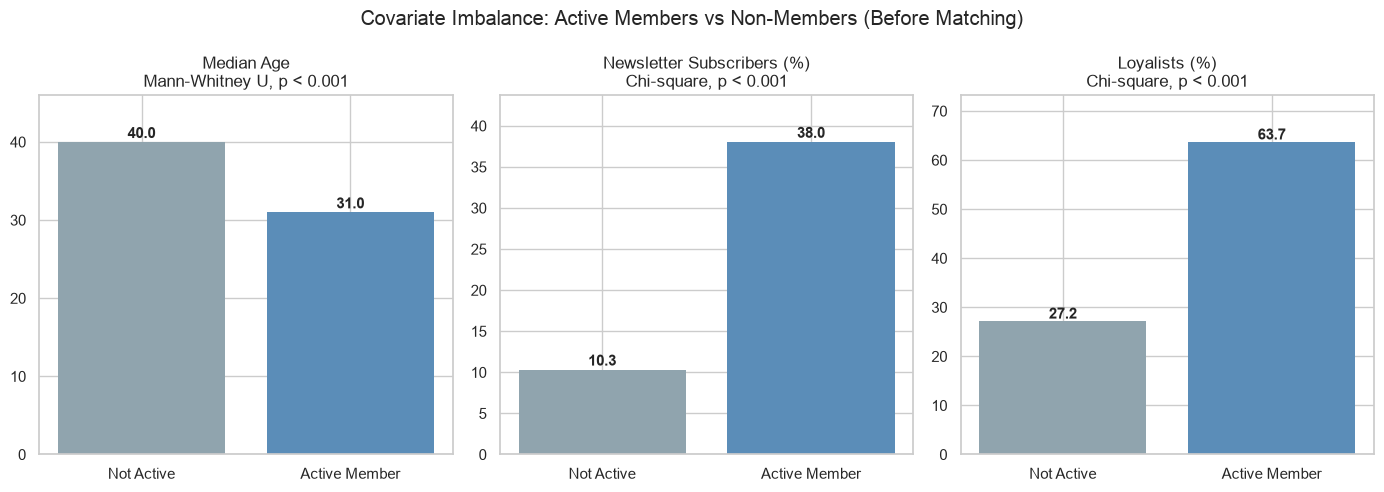

In [53]:
from scipy.stats import chi2_contingency
from scipy import stats

age_active = rfm[rfm['club_active'] == 1]['age'].dropna()
age_inactive = rfm[rfm['club_active'] == 0]['age'].dropna()
_, p_age = stats.mannwhitneyu(age_active, age_inactive, alternative='two-sided')

news_ct = pd.crosstab(rfm['club_active'], rfm['fashion_news_frequency'] != 'NONE')
_, p_news, _, _ = chi2_contingency(news_ct)

seg_ct = pd.crosstab(rfm['club_active'], rfm['segment'] == 'Loyalists')
_, p_seg, _, _ = chi2_contingency(seg_ct)

balance = rfm.groupby('club_active').agg(
    median_age=('age', 'median'),
    pct_subscribed=('fashion_news_frequency', lambda x: (x != 'NONE').mean() * 100),
    pct_loyalist=('segment', lambda x: (x == 'Loyalists').mean() * 100),
).round(2)
balance.index = ['Not Active', 'Active Member']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

vars_to_plot = ['median_age', 'pct_subscribed', 'pct_loyalist']
base_labels = ['Median Age', 'Newsletter Subscribers (%)', 'Loyalists (%)']
p_values = [p_age, p_news, p_seg]
tests = ['Mann-Whitney U', 'Chi-square', 'Chi-square']

for ax, var, label, p, test in zip(axes, vars_to_plot, base_labels, p_values, tests):
    p_str = 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
    ax.bar(balance.index, balance[var], color=['#90A4AE', '#5B8DB8'], edgecolor='none')
    for i, val in enumerate(balance[var]):
        ax.text(i, val + 0.5, f'{val:.1f}', ha='center', fontsize=11, fontweight='bold')
    ax.set_title(f'{label}\n{test}, {p_str}')
    ax.set_ylim(0, balance[var].max() * 1.15)

plt.suptitle('Covariate Imbalance: Active Members vs Non-Members (Before Matching)')
plt.tight_layout()
plt.show()

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

psm_df = rfm[['customer_id', 'club_active', 'age',
              'fashion_news_frequency', 'segment',
              'recency', 'frequency', 'monetary']].dropna().copy()

psm_df['subscribed'] = (psm_df['fashion_news_frequency'] != 'NONE').astype(int)
psm_df = pd.get_dummies(psm_df, columns=['segment'], drop_first=True)

feature_cols = ['age', 'subscribed'] + [c for c in psm_df.columns if c.startswith('segment_')]

lr_ps = LogisticRegression(max_iter=1000)
lr_ps.fit(psm_df[feature_cols], psm_df['club_active'])
psm_df['propensity'] = lr_ps.predict_proba(psm_df[feature_cols])[:, 1]

active = psm_df[psm_df['club_active'] == 1].copy()
inactive = psm_df[psm_df['club_active'] == 0].copy()

nn = NearestNeighbors(n_neighbors=1)
nn.fit(inactive[['propensity']])
distances, indices = nn.kneighbors(active[['propensity']])

matched_controls = inactive.iloc[indices.flatten()].copy()
matched_treated = active.copy()

print(f"Matched pairs: {len(matched_treated):,}")
pd.DataFrame({
    'Active Member': matched_treated[['age', 'subscribed', 'propensity']].mean(),
    'Not Active': matched_controls[['age', 'subscribed', 'propensity']].mean()
}).round(3)

Matched pairs: 1,245,163


,Active Member,Not Active
age,36.076,36.070
subscribed,0.375,0.375
propensity,0.939,0.939


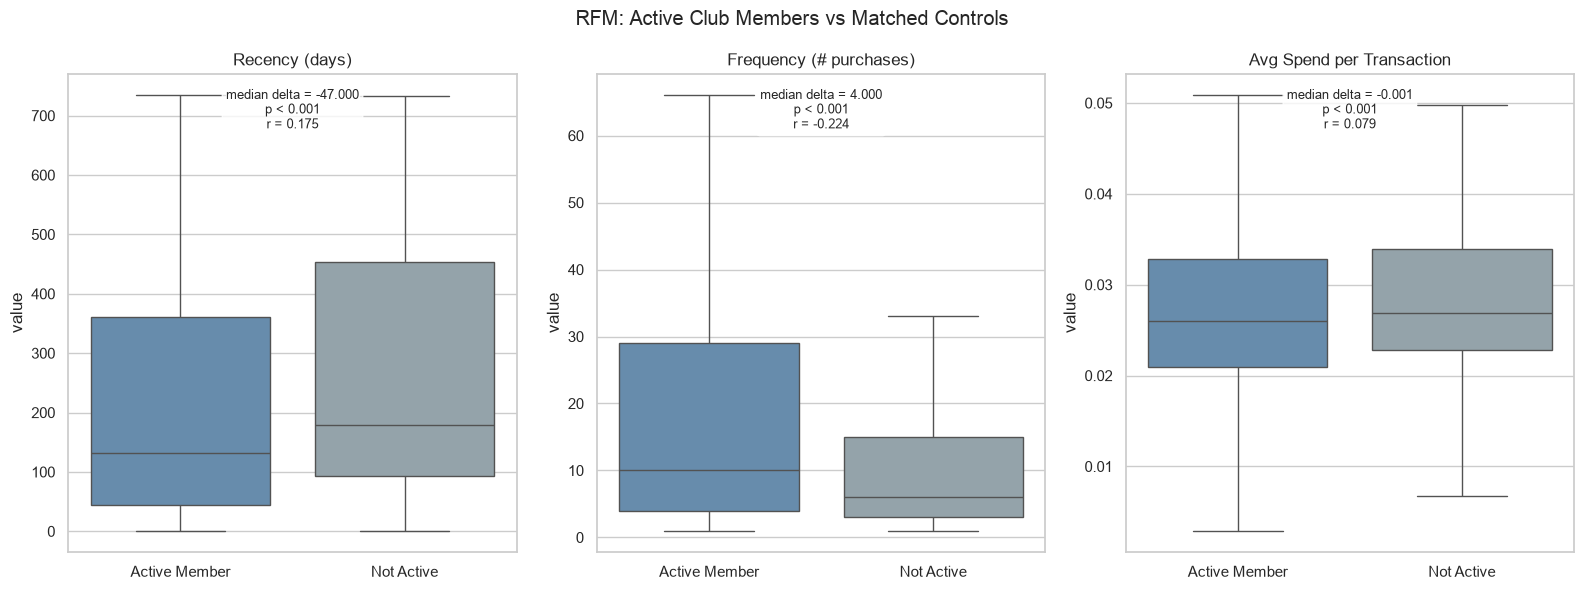

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

metrics = ['recency', 'frequency', 'monetary']
titles = ['Recency (days)', 'Frequency (# purchases)', 'Avg Spend per Transaction']

for ax, metric, title in zip(axes, metrics, titles):
    treated_vals = matched_treated[metric].values
    control_vals = matched_controls[metric].values
    
    stat, p = stats.mannwhitneyu(treated_vals, control_vals, alternative='two-sided')
    n1, n2 = len(treated_vals), len(control_vals)
    effect_size = 1 - (2 * stat) / (n1 * n2)
    med_diff = np.median(treated_vals) - np.median(control_vals)
    
    plot_df = pd.DataFrame({
        'value': np.concatenate([treated_vals, control_vals]),
        'group': ['Active Member'] * n1 + ['Not Active'] * n2
    })
    
    sns.boxplot(data=plot_df, x='group', y='value',
                hue='group', palette=['#5B8DB8', '#90A4AE'],
                legend=False, showfliers=False, ax=ax)
    
    ax.set_title(title)
    ax.set_xlabel('')
    
    p_str = 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
    ax.text(0.5, 0.97,
            f'median delta = {med_diff:.3f}\n{p_str}\nr = {effect_size:.3f}',
            transform=ax.transAxes, ha='center', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

plt.suptitle('RFM: Active Club Members vs Matched Controls')
plt.tight_layout()
plt.show()

After matching on age, newsletter subscription, and segment, the club membership association is most noticeable in terms of Frequency and statistically significant in all categories. Active members are more recently active (median delta = -47, r = 0.175) and purchase more frequently (median delta = 4000, r = -0.224), with marginally lower average spend per transaction (median delta = -0.001, r = 0.079).

This is observational, so we can't say whether club membership is strictly causing the engagement difference. That said, the effect on frequency is worth noting, as it suggests the club program may be more effective at driving repeat visits than shifting customers toward higher price points.

## Overall Conclusions

Three customer groups emerge from the clustering. Loyalists (61%) are recent and frequent but spend at lower price points. High-Value Occasionals (9%) are less frequent but consistently outspend the other segments. Lapsed customers (30%) haven't purchased in over 500 days, and their spending pattern looks more like HVOs than Loyalists.

The most concrete opportunity visible in the data is in Garment Upper Body: Loyalists transact in this category at high volume but at a lower price point than HVOs. Even a small shift in spend per visit would add up quickly given the transaction volume.

The club membership association appears to be a strong differentiator in consumer behavior, although additional investigation into this effect would be a good idea.

An important limitation to point out: This dataset uses normalized prices, so the revenue uplift estimates are relative rather than in actual currency.

In [56]:
rfm_export = rfm[['customer_id', 'recency', 'recency_resid', 'frequency', 
                   'monetary', 'cluster', 'segment', 'age', 
                   'club_member_status', 'fashion_news_frequency',
                   'pc1', 'pc2']].copy()

rfm_export.to_csv('data/rfm_clusters.csv', index=False)
print(f"Exported {len(rfm_export):,} rows")

Exported 1,362,281 rows
